In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [46]:
# Choose correct data files:

df_precip = pd.read_csv('target_precip_SWE_lin_moanom.csv')

In [47]:
df_precip['time'] = pd.to_datetime(df_precip['time'])
df_precip

,time,tp
0,1950-12-04,0.946598
1,1950-12-05,1.087024
2,1950-12-06,1.038866
3,1950-12-07,0.661627
4,1950-12-08,0.585449
...,...,...
6295,2025-02-21,-0.268537
6296,2025-02-22,0.059818
6297,2025-02-23,0.189314
6298,2025-02-24,0.277404


In [48]:
df_precip_train = df_precip[df_precip['time'] < "2010-07"]
df_precip_test = df_precip[df_precip['time'] > "2010-07"]

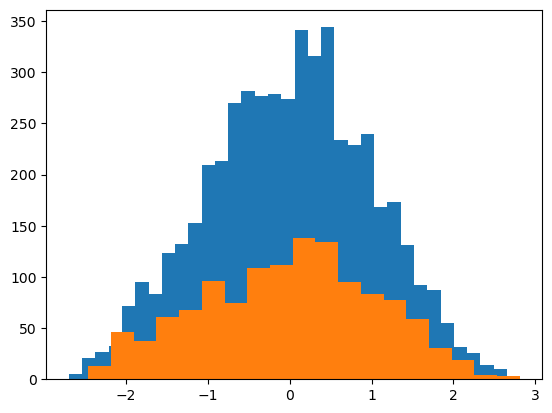

In [49]:
plt.hist(df_precip_train['tp'], bins='auto')
plt.hist(df_precip_test['tp'], bins='auto')
plt.show()

In [50]:
upper_quantile_precip = df_precip_train.quantile([0.9])['tp'].values[0]
print(upper_quantile_precip)

1.2978833464876296


In [51]:
df_precip['quantile_category'] = 0
df_precip['quantile_category'] = df_precip['quantile_category'].where(df_precip['tp'] < upper_quantile_precip, 1)

In [52]:
df_precip

,time,tp,quantile_category
0,1950-12-04,0.946598,0
1,1950-12-05,1.087024,0
2,1950-12-06,1.038866,0
3,1950-12-07,0.661627,0
4,1950-12-08,0.585449,0
...,...,...,...
6295,2025-02-21,-0.268537,0
6296,2025-02-22,0.059818,0
6297,2025-02-23,0.189314,0
6298,2025-02-24,0.277404,0


In [53]:
df_precip = df_precip.drop(['tp'], axis=1).set_index('time')

In [54]:
print(len(df_precip[(df_precip.index < "2010-07") & (df_precip['quantile_category'] == 0)])/5040)
print(len(df_precip[(df_precip.index < "2010-07") & (df_precip['quantile_category'] == 1)])/5040)

0.9
0.1


In [55]:
print(len(df_precip[(df_precip.index > "2010-07") & (df_precip['quantile_category'] == 0)])/1260)
print(len(df_precip[(df_precip.index > "2010-07") & (df_precip['quantile_category'] == 1)])/1260)

0.8849206349206349
0.11507936507936507


In [56]:
# Name data files appropriately:

df_precip.to_csv('southwestern_precipitation_90_cat.csv')